In [1]:
'''Primeramente, vamos a instalar las dependencias necesarias para realizar
las consultas dentro de la base de datos LOTUS'''
%pip install pandas
%pip install rdkit py3Dmol


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 46.0 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rdkit]32m1/2 [rdkit]


In [4]:
'''Luego, se importan las bibliotecas Requests, Pandas, RDKit y sus módulos Chem y Draw'''
import pandas as pd
import requests
from rdkit import Chem
from rdkit.Chem import Draw

Luego, podemos hacer una búsqueda sencilla empleando el nombre de un producto natural como por ejemplo, el mentol, presente en productos cosméticos como labiales, esencias y el famoso Vaporrub.

> [!WARNING] 
> Los nombres de los compuestos deben estar exclusivamente en inglés

Status code del query: 200
Estructura química del query "digoxin"


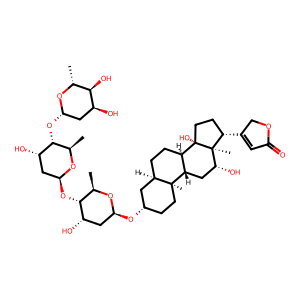

In [100]:
'''Búsqueda por nombre:

Nos van a solicitar el nombre de un producto natural, para posteriormente ejecutar un query simple a la API REST de LOTUS.
Este bloque nos va a devolver el status del query y la estrucutra química del compuesto que estamos buscando'''

compound=input("Introduce el nombre de un producto natural (en inglés):")
url=f"https://lotus.naturalproducts.net/api/search/simple?query={compound}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
df=pd.json_normalize(data,record_path=['naturalProducts'],meta=['originalQuery','determinedInputType'])
smiles=df.loc[0,'smiles']
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{compound}\"")
img


O, podemos emplear una búsqueda por SMILES de la estructura de la molécula
Por ejemplo, podemos buscar:
- Menthol, el compuesto responsable del aroma a menta de *Menta piperita* (menta): C[C@@H]1CC[C@H]([C@@H](C1)O)C(C)C
- Cocaine, un alcaloide de la planta de coca (*Erythroxylum coca*): COC(=O)[C@H]1[C@@H](OC(=O)c2ccccc2)C[C@@H]2CC[C@H]1N2C
- Geraniol, presente en las flores de geranio (*Geranium* sp.): CC(=CCC/C(=C/CO)/C)C
- Delphinidin, una antociandinina que da colores azules a flores como las dalias y las petunias: C1=C(C=C(C(=C1O)[O-])O)C2=C(C=C3C(=CC(=O)C=C3O2)O)O 

Status code del query: 200
{'originalQuery': 'Cn1c(=O)c2c(ncn2C)n(C)c1=O', 'count': 9, 'naturalProducts': [{'id': None, 'lotus_id': 'LTS0075508', 'wikidata_id': None, 'contains_sugar': None, 'heavy_atom_number': None, 'smiles': 'Cn1c(=O)c2c(ncn2C)n(C)c1=O', 'inchi': None, 'inchikey': None, 'inchi2D': None, 'inchikey2D': None, 'smiles2D': 'Cn1c(=O)c2c(ncn2C)n(C)c1=O', 'sugar_free_smiles': None, 'deep_smiles': '', 'traditional_name': 'caffeine', 'synonyms': None, 'cas': None, 'iupac_name': None, 'contains_ring_sugars': False, 'contains_linear_sugars': False, 'collection': [], 'molecular_formula': 'C8H10N4O2', 'molecular_weight': 194.19091739584468, 'npl_noh_score': None, 'npl_score': 1.0, 'npl_sugar_score': None, 'number_of_carbons': None, 'number_of_nitrogens': None, 'number_of_oxygens': None, 'number_of_rings': None, 'max_number_of_rings': None, 'min_number_of_rings': None, 'number_repeated_fragments': None, 'sugar_free_heavy_atom_number': None, 'sugar_free_total_atom_number': None, 't

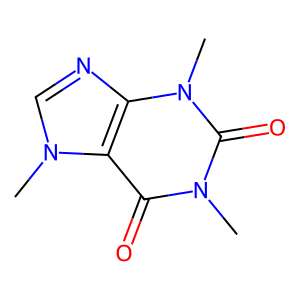

In [26]:
smiles=input("Introduce el SMILES de una molécula aquí")
url=f"https://lotus.naturalproducts.net/api/search/substructure?type=vf&max-hits=10&smiles={smiles}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
print(data)
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{smiles}\"")
img



In [92]:
''' Este es el armado de nuestro query en 3D, esta celda acepta tanto el output de un query por nombre como
del query por código SMILES'''

from rdkit.Chem import AllChem, rdCoordGen
from rdkit.Chem.Draw import IPythonConsole 
IPythonConsole.ipython_useSVG=True
import py3Dmol

'''Armado, inserción de átomos de hidrógeno y optimización con MMFF94
La función recibe un objeto mol de RDKit, para posteriormente generar
coordenadas XYZ para cada átomo que constituye la molécula'''

def mol3d(mol):
    mol=Chem.MolFromSmiles(smiles)
    rdCoordGen.AddCoords(mol)
    mol=Chem.AddHs(mol,addCoords=True)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol
mol=mol3d(mol=smiles)

view = py3Dmol.view(
    data=Chem.MolToMolBlock(mol),  # Convert the RDKit molecule for py3Dmol
    style={"stick": {}, "sphere": {"scale": 0.3}}
)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [102]:
# Organizando los datos en un dataframe de Pandas
df=pd.json_normalize(data['naturalProducts'])
df=df.dropna(axis=1,how='all')
df=df.drop_duplicates(['molecular_weight'])
df.drop(list(df.filter(regex="fragment*")),axis=1,inplace=True)
# Vamos a imprimir varias características de nuestra tabla
print("¿Cuántas filas y columnas tiene el archivo?","\n",df.shape[0],"columnas y", df.shape[1],"filas\n")
print("Esta es la descripción de la tabla:\n")
df=df.filter(['id','lotus_id','traditional_name','molecular_weight','contains_sugar','smiles'])
display(df)

¿Cuántas filas y columnas tiene el archivo? 
 2 columnas y 212 filas

Esta es la descripción de la tabla:



,id,lotus_id,traditional_name,molecular_weight,contains_sugar,smiles
0,604b82de12e499616274a006,LTS0162755,digoxin,780.940049,0,C[C@H]1O[C@@H](O[C@H]2[C@@H](O)C[C@H](O[C@H]3[...
1,604b892e12e4996162759b21,LTS0099256,digoxin ester derivative,822.976807,0,CC(=O)OC1CC(OC2C(O)CC(OC3C(O)CC(OC4CCC5(C)C(CC...


Algunos productos naturales existen como **agliconas** y **gliconas**, siendo una aglicona la forma sin azúcar y la glicona la forma unida a uno o más azúcares. 

Ejemplos de productos naturales de esta naturaleza son:

- **Antocianinas y antocianidinas**: Las antocinaninas son compuestos responsables de colores rojizos, morados, rosas y azulados en flores, frutos y hojas de algunas especies de plantas. Estos compuestos son sensibles a la acidez del suelo y, en flores como las dahlias y las petuñas, el color de la flor es indicativo del pH aproximado del suelo. Por otro lado, las antocianinas son la forma de glicona de las antocianidinas, estas últimas siendo la forma sin azúcares de las antocianinas. Ejemplos son la delfinidina (aglicona) y la delfinidina 3-glucósido (glicona).

- **Glicósidos cardiotónicos**: Los glicósidos cardiotónicos son compuestos derivados de una aglicona de esterol vegetal unida a azúcares, tienen un intensivo uso en la medicina como tratamiento para afecciones cardíacas. Ejemplos de glicósidos cardiotónicos son la digoxina (*digoxin*) y la digitoxina (*digitoxin*), de la planta *Digitalis purpurea* o digital.

En la siguiente celda, haremos un agrupamiento según la si hay o no azúcares unidos a las estructuras dentro de nuestro data frame. Esta celda arrojará 0 si la columna `'contains_sugar'` está vacía.

In [103]:
display(df.groupby('contains_sugar').count()['lotus_id'])
print(f"En la tabla, tenemos {df[df['contains_sugar'] != 0]['id'].count()} producto(s) natural(es) en su forma glicona\ny {df[df['contains_sugar'] == 0]['id'].count()} producto(s) natural(es) en su forma algicona ")

,lotus_id
contains_sugar,
0,2


En la tabla, tenemos 0 producto(s) natural(es) en su forma glicona
y 2 producto(s) natural(es) en su forma algicona 


Estructuras moleculares similares a nuestro query C[C@H]1O[C@@H](O[C@H]2[C@@H](O)C[C@H](O[C@H]3[C@@H](O)C[C@H](O[C@H]4CC[C@]5(C)[C@H]6C[C@@H](O)[C@]7(C)[C@@H](C8=CC(=O)OC8)CC[C@]7(O)[C@@H]6CC[C@@H]5C4)O[C@@H]3C)O[C@@H]2C)C[C@H](O)[C@@H]1O
0                     digoxin
1    digoxin ester derivative
Name: traditional_name, dtype: object


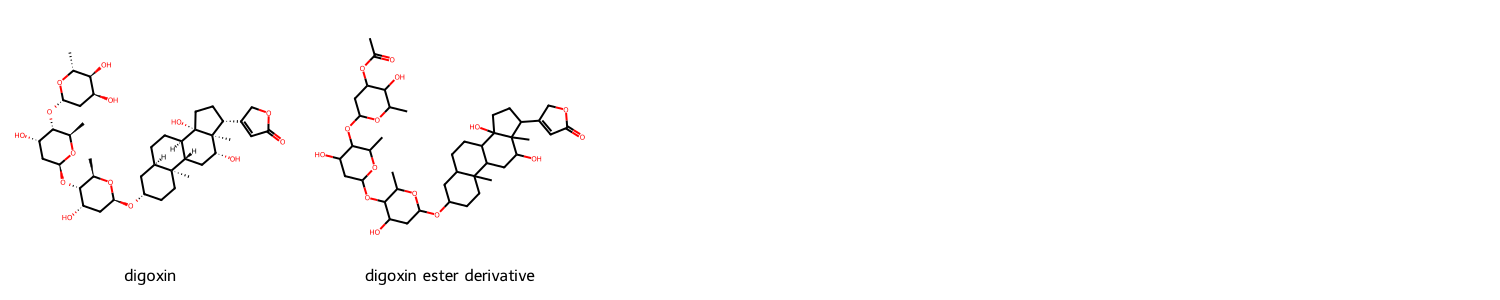

In [104]:
'''
La ventaja de una base de datos como LOTUS es que permite encontrar compuestos con estructuras similares
al de nuestro interés.
Esta celda lo que hace es rescatar todos los códigos SMILES dentro de nuestro data frame y los acomoda en una
imagen compuesta por todos los resultados similares al query (maxhits=int)
'''
mol =  [ Chem.MolFromSmiles(x) for x in df['smiles']]
names=list(df['traditional_name'])
img=Draw.MolsToGridImage(mol,molsPerRow=5,legends=names,subImgSize=(300,300))  
print(f"Estructuras moleculares similares a nuestro query {smiles}")
print(df['traditional_name'])
img